# Libraries

In [96]:
import numpy as np
import tensorflow as tf
from skimage import color, io
from skimage.transform import resize
import cv2
import os
from skimage.color import rgb2lab
import matplotlib.pyplot as plt
from skimage.color import lab2rgb
from skimage.transform import rotate

# Model Preperation

In [97]:
MODEL_PATH = 'Colorized-Img/Colorized-Img/colorize_autoencoder_first1000.keras'

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
print("Model loaded successfully!")
model.summary()


Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 256, 256, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 256, 256, 2)    │         1,154 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 3,105,346 (11.85 MB)

 Trainable params: 3,102,530 (11.84 MB)

 Non-trainable params: 2,816 (11.00 KB)

# Preprocessing

This section prepares the input images for the colorization model by converting them to grayscale, which is then used in the preprocessing pipeline.

## Converting Images to Grayscale

In [98]:
input_folder = "Colorized-Img/"
output_folder = "Grey-Img/"

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

rgb_imgs = []
for filename in os.listdir(input_folder):
    if filename.lower().endswith(('.jpg', '.jpeg')):
        input_path = os.path.join(input_folder, filename)
        output_path = os.path.join(output_folder, filename)
        
        img = cv2.imread(input_path)
        
        rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        rgb_imgs.append(rgb_img)
        if img is not None:
            grey_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            cv2.imwrite(output_path, grey_img)
            print(f"Converted: {filename}")
        else:
            print(f"Skipped (could not read): {filename}")

print("All done!")

Converted: forest.397.jpg
Converted: forest.399.jpg
Converted: YIN8QU2CC97X.jpg
Converted: ZYLOMHW6DWLE.jpg
All done!


## Converting to LAB format and Extracting L channel

### First Method

This part converts the grayscale image into a pseudo-RGB image by stacking the grayscale channel three times, then transforms it to Lab and extracts the L channel. The L channel is also stored in its original 0 to 100 range for later experiments.

In [99]:
def converting_to_lab_first_method(output_folder,mode='normal'):
    L_channels  = []
    L_channels_raw = []
    for filename in os.listdir(output_folder):
        if filename.lower().endswith(('.jpg', '.jpeg')):
            input_path = os.path.join(output_folder, filename)        
            gray_img = cv2.imread(input_path, cv2.IMREAD_GRAYSCALE)
                        
            if gray_img is not None:
                gray_resized = cv2.resize(gray_img, (256, 256))
                rgb_like = np.stack([gray_resized, gray_resized, gray_resized], axis=-1)

                rgb_like_normalized = rgb_like / 255.0
                lab_img = rgb2lab(rgb_like_normalized)

                L_channel = lab_img[:, :, 0]
                
                if mode == 'noise':
                    noise = np.random.normal(loc=0.0, scale=0.1, size=L_channel.shape)
                    L_channel = L_channel + noise
                    L_channel = np.clip(L_channel, 0, 100)
                    
                elif mode == 'dark':
                    L_channel = L_channel * 0.7
                    
                elif mode == 'bright':
                    L_channel = L_channel * 1.3
                    L_channel = np.clip(L_channel, 0, 100)

                
                L_channels_raw.append(L_channel)
                L_channel_3d = np.expand_dims(L_channel, axis=(0,-1))
                L_channels.append(L_channel_3d)
            else:
                print(f"Skipped (could not read): {filename}")
    L_channels_array = np.array(L_channels)
    
    return L_channels_array,L_channels_raw



    

### Second Method

This method converts the original RGB image directly to Lab and extracts the L channel. Since it starts from the true color image, it usually preserves luminance information more naturally.

In [100]:
def converting_to_lab_second_method(output_folder):
    L_channels  = []
    L_channels_raw = []
    for filename in os.listdir(output_folder):
        if filename.lower().endswith(('.jpg', '.jpeg')):
            input_path = os.path.join(output_folder, filename)        
            bgr_img = cv2.imread(input_path, cv2.IMREAD_COLOR)
            if bgr_img is not None:
                rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
                rgb_resized = cv2.resize(rgb_img, (256, 256))
                rgb_normalized = rgb_resized / 255.0
                lab_img = rgb2lab(rgb_normalized)
                L_channel = lab_img[:, :, 0]
                L_channels_raw.append(L_channel)
                L_channel_3d = np.expand_dims(L_channel, axis=(0,-1))
                L_channels.append(L_channel_3d)
            else:
                print(f"Skipped (could not read): {filename}")
    L_channels_array = np.array(L_channels)
    
    return L_channels_array,L_channels_raw




## Usage

The next cells run both preprocessing methods on the dataset and prepare the L-channel inputs for evaluation.

### First Method

In [101]:
L_channels_first_method,L_channels_raw_first_method = converting_to_lab_first_method(output_folder)
print("Shape:", L_channels_first_method[0].shape)

Shape: (1, 256, 256, 1)


### Second Method

In [102]:
L_channels_second_method,L_channels_raw_second_method = converting_to_lab_second_method(output_folder)
print("Shape:", L_channels_second_method[0].shape)

Shape: (1, 256, 256, 1)


## Evaluate

The trained model predicts the a and b channels from the prepared L-channel inputs.

In [103]:
def evaluate(model,L_channels):
    ab_predicteds = []
    for X_input in L_channels:
        ab_predicted = model.predict(X_input)
        ab_predicteds.append(ab_predicted)
    return ab_predicteds


In [104]:
ab_predicteds_first_method = evaluate(model,L_channels_first_method)
ab_predicteds_second_method = evaluate(model,L_channels_second_method)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


## Plot Output of Original Inputs

These plots compare the original image with the outputs of the two preprocessing methods. The side-by-side view helps judge which output looks more natural.

In [105]:
def plot_colorized_comparison(L_raw_first,L_raw_second, ab_first, ab_second, original_rgbs, rotate_flag=False):
    rgbs_first = []

    for i in range(4):
        ab_out1 = ab_first[i] * 128.0
        lab1 = np.zeros((256, 256, 3), dtype=np.float64)
        lab1[:, :, 0] = L_raw_first[i]
        lab1[:, :, 1:] = ab_out1
        rgb1 = lab2rgb(lab1)
        rgbs_first.append(rgb1)
        ab_out2 = ab_second[i] * 128.0
        lab2 = np.zeros((256, 256, 3), dtype=np.float64)
        lab2[:, :, 0] = L_raw_second[i]
        lab2[:, :, 1:] = ab_out2
        rgb2 = lab2rgb(lab2)
        
        rgb_orig = original_rgbs[i]

        if rotate_flag:
            rgb1 = rotate(rgb1, angle=-45, resize=False, mode='constant', cval=0)
            rgb2 = rotate(rgb2, angle=-45, resize=False, mode='constant', cval=0)
            rgb_orig = rotate(rgb_orig, angle=-45, resize=False, mode='constant', cval=0)

        plt.figure(figsize=(18, 6))
        
        plt.subplot(1, 3, 1)
        plt.title(f"Image {i+1}: Original RGB")
        plt.imshow(rgb_orig)
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.title("First Method Colorization")
        plt.imshow(rgb1)
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.title("Second Method Colorization")
        plt.imshow(rgb2)
        plt.axis('off')

        plt.tight_layout()
        plt.show()
    return rgbs_first


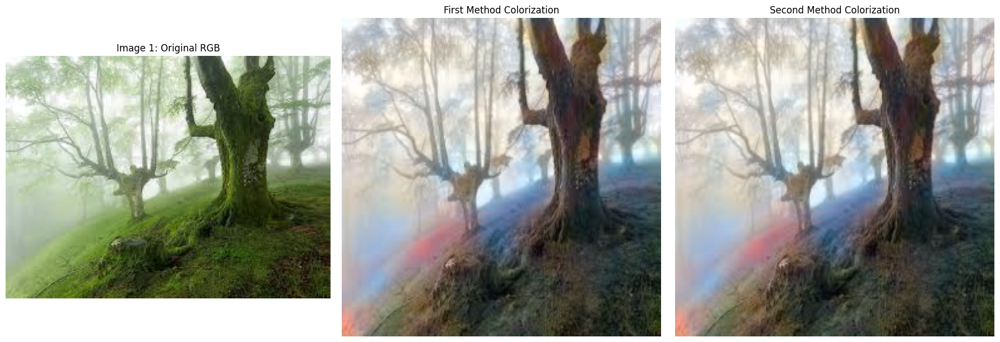

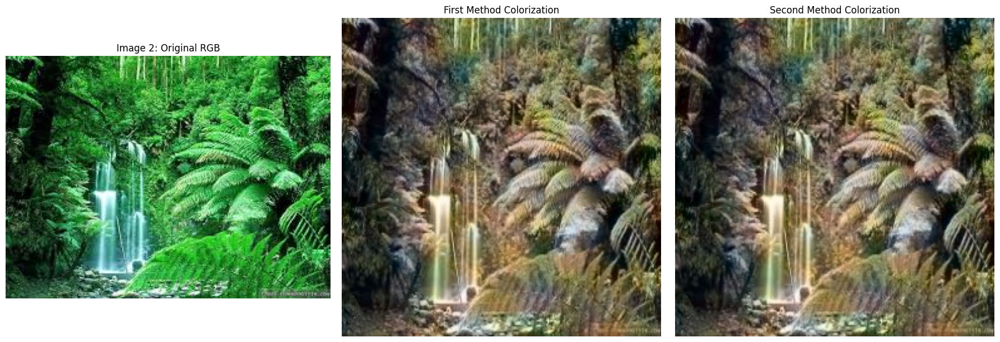

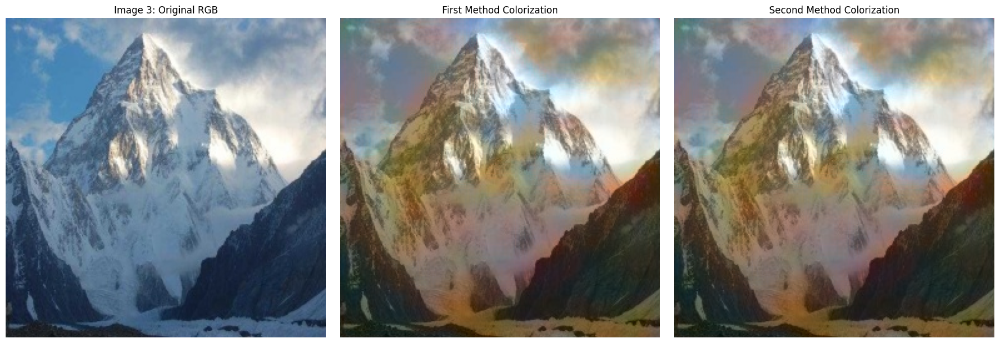

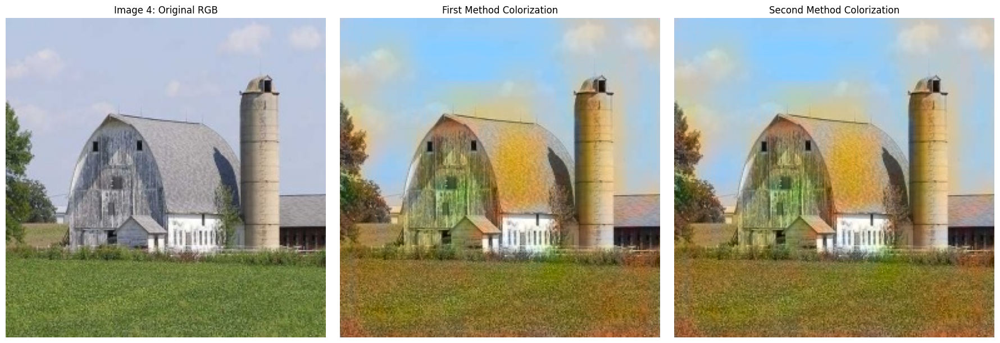

In [106]:
rgbs_first = plot_colorized_comparison(L_channels_raw_first_method,L_channels_raw_second_method, ab_predicteds_first_method, ab_predicteds_second_method, rgb_imgs, rotate_flag=False)

## Rotation, Gaussian Noise and Brightness

### Image Rotation

In [107]:

input_folder = "Grey-Img/"
output_folder = "Rotated-Img/"

if not os.path.exists(output_folder):
    os.makedirs(output_folder)


for filename in os.listdir(input_folder):
    if filename.lower().endswith(('.jpg', '.jpeg')):
        input_path = os.path.join(input_folder, filename)
        output_path = os.path.join(output_folder, filename)
        
        img = cv2.imread(input_path)
        
        if img is not None:
            img = cv2.resize(img, (256, 256))
            (h, w) = img.shape[:2]

            center = (w // 2, h // 2)

            
            matrix_45 = cv2.getRotationMatrix2D(center, 45, 1.0)
            rotated_45 = cv2.warpAffine(img, matrix_45, (w, h))
            cv2.imwrite(output_path, rotated_45)
            print(f"Rotated: {filename}")
        else:
            print(f"Skipped (could not read): {filename}")

print("All done!")

Rotated: forest.397.jpg
Rotated: forest.399.jpg
Rotated: YIN8QU2CC97X.jpg
Rotated: ZYLOMHW6DWLE.jpg
All done!


### Converting to lab Format

In [108]:
L_channels_rotate,L_channels_raw_rotate = converting_to_lab_first_method(output_folder)
L_channels_noisy,L_channels_raw_noisy = converting_to_lab_first_method(input_folder,'noise')
L_channels_dark,L_channels_raw_dark = converting_to_lab_first_method(input_folder,'dark')
L_channels_bright,L_channels_raw_bright = converting_to_lab_first_method(input_folder,'bright')


### Evaluate

In [109]:
ab_predicteds_rotate = evaluate(model,L_channels_rotate)
ab_predicteds_noisy = evaluate(model,L_channels_noisy)
ab_predicteds_dark = evaluate(model,L_channels_dark)
ab_predicteds_bright = evaluate(model,L_channels_bright)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


### Ploting Results

In [110]:
def plot_colorized_modified(L_channels_raw, ab_predicteds, original_rgbs,output_log, rotate_flag=False):
    for i in range(4):
        ab_out = ab_predicteds[i] * 128.0
        predicted_lab = np.zeros((256, 256, 3), dtype=np.float64)
        predicted_lab[:, :, 0] = L_channels_raw[i]
        predicted_lab[:, :, 1:] = ab_out

        colorized_rgb = lab2rgb(predicted_lab)
        
        original_rgb = original_rgbs[i]

        if rotate_flag:
            colorized_rgb = rotate(colorized_rgb, angle=-45, resize=False, mode='constant', cval=0)

        plt.figure(figsize=(12, 6))
        
        plt.subplot(1, 2, 1)
        plt.title(f"Image {i+1}: Output from Original Image")
        plt.imshow(original_rgb)
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.title("Output from "+ output_log)
        plt.imshow(colorized_rgb)
        plt.axis('off')

        plt.tight_layout()
        plt.show()


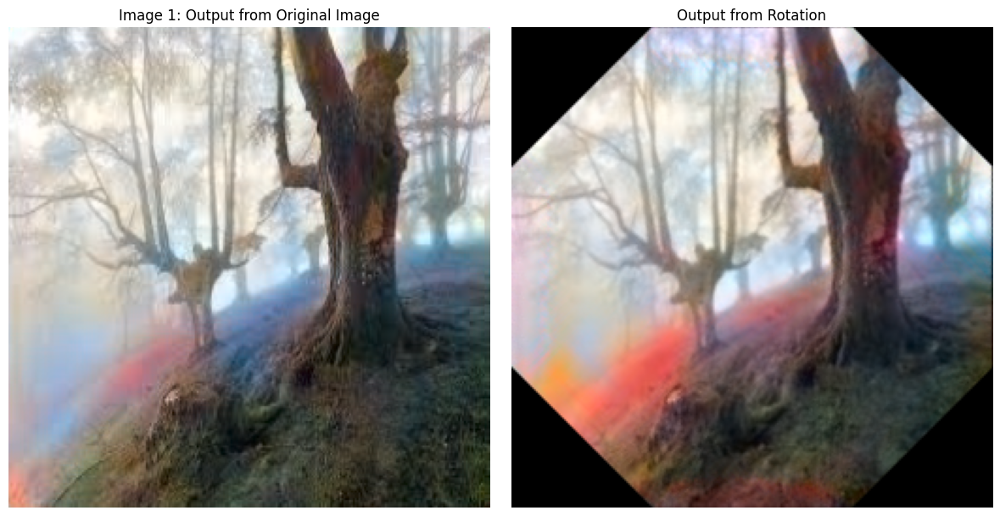

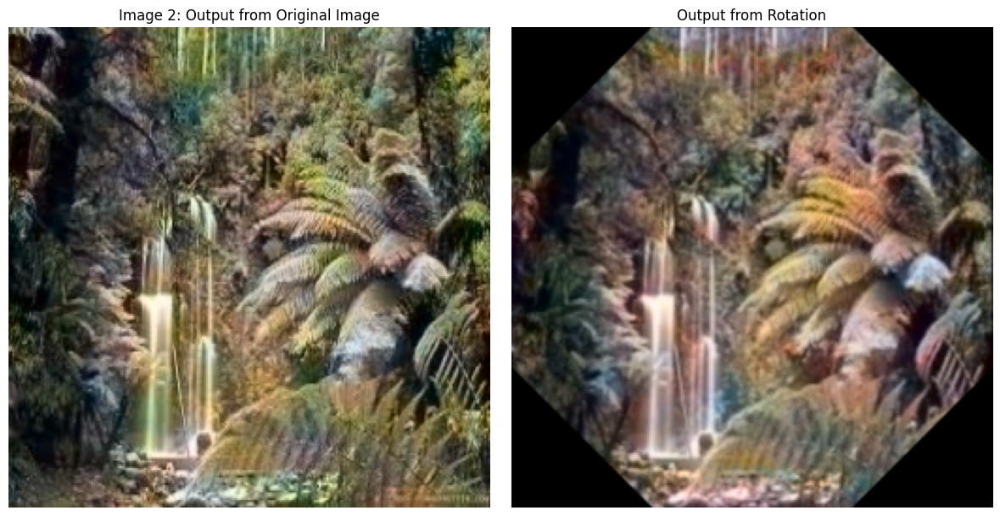

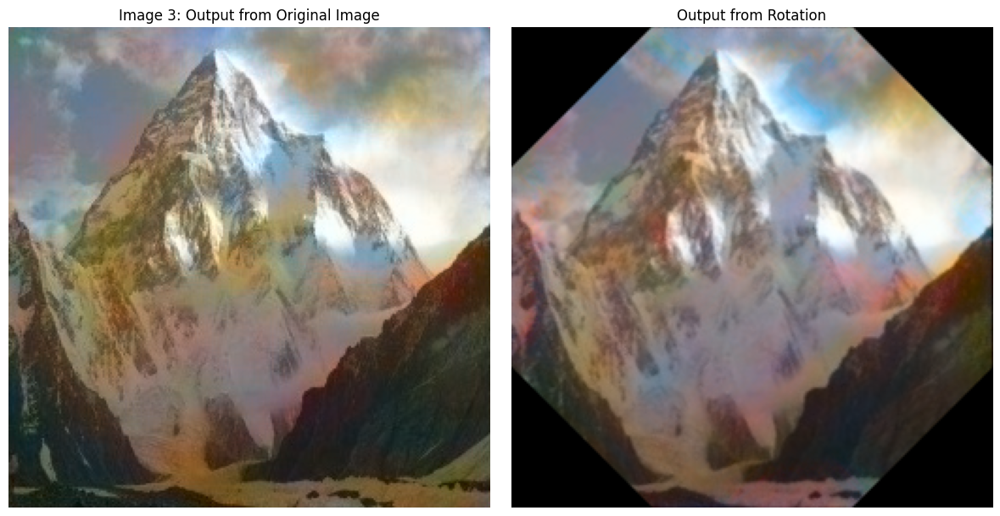

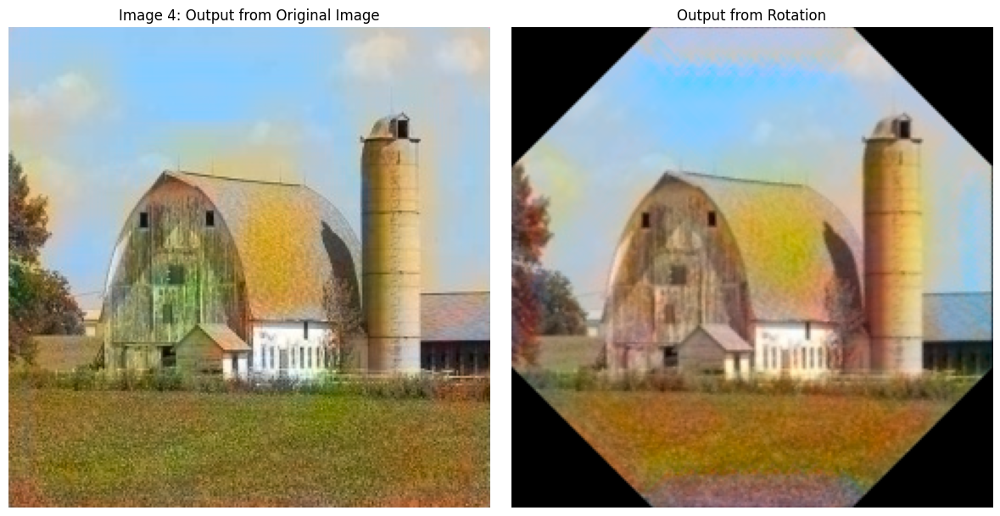

In [111]:
plot_colorized_modified(L_channels_raw_rotate, ab_predicteds_rotate, rgbs_first,"Rotation", True)

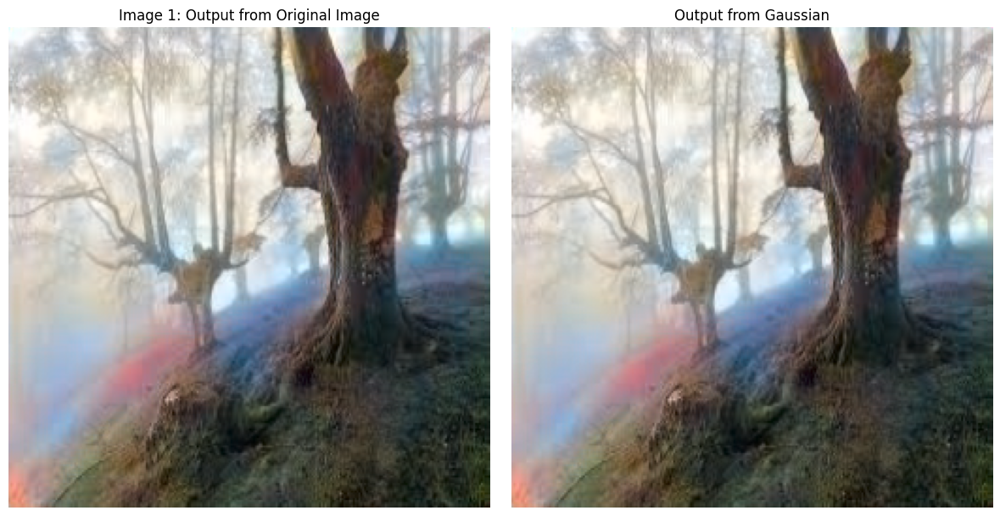

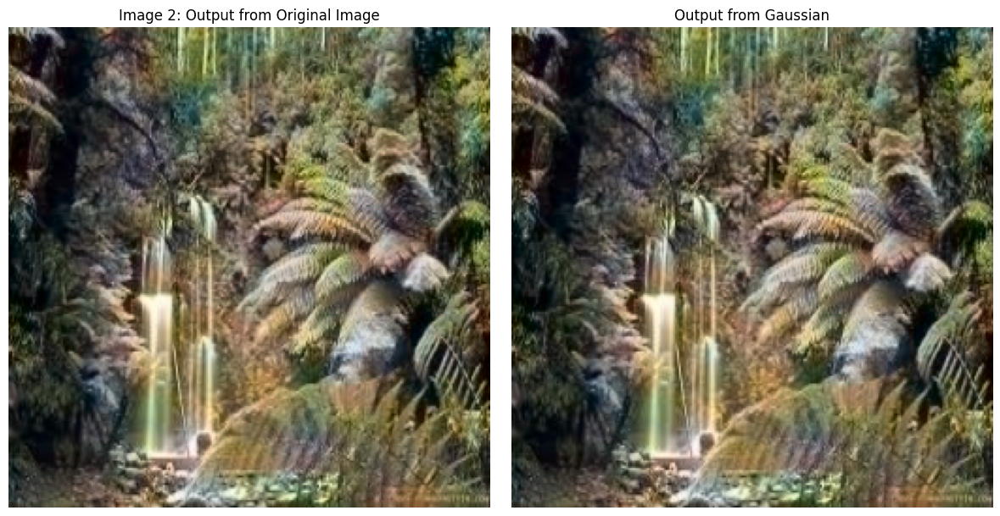

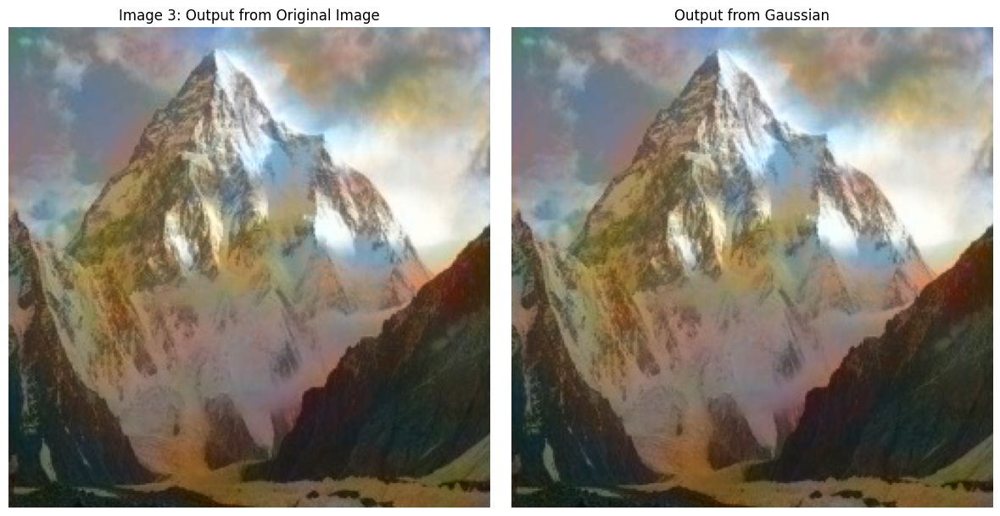

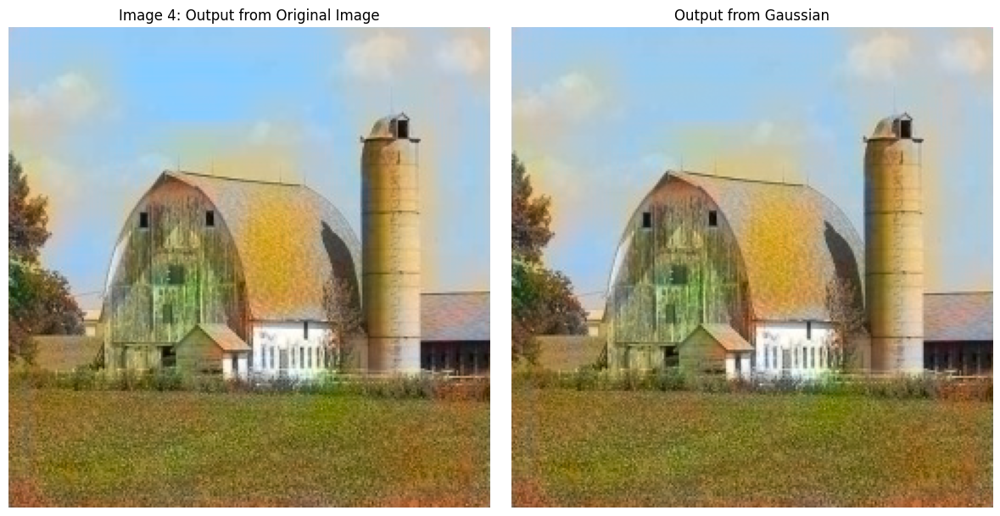

In [112]:
plot_colorized_modified(L_channels_raw_noisy, ab_predicteds_noisy, rgbs_first, "Gaussian",False)

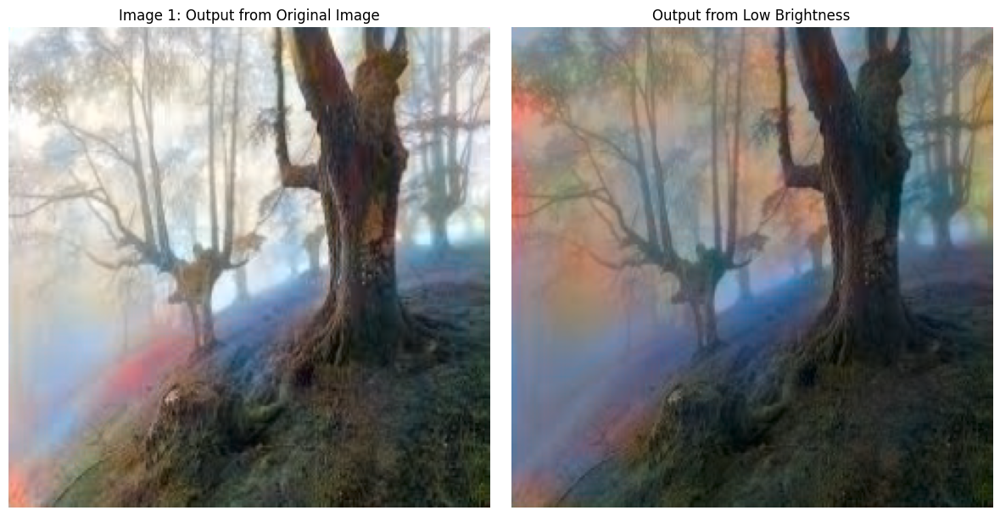

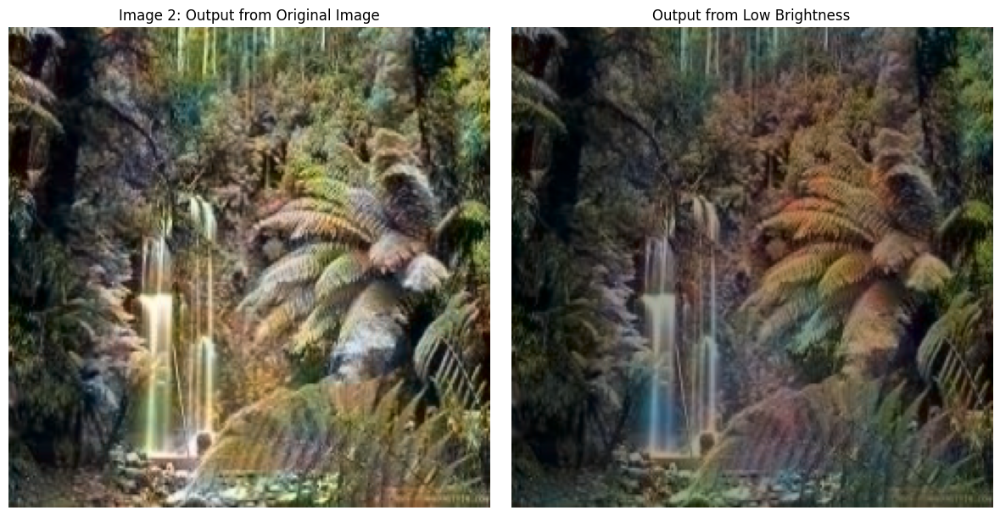

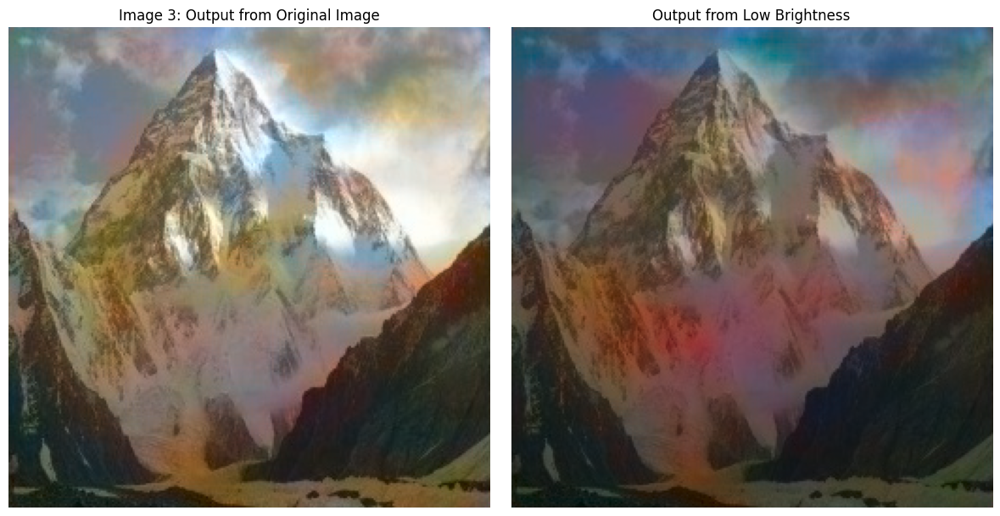

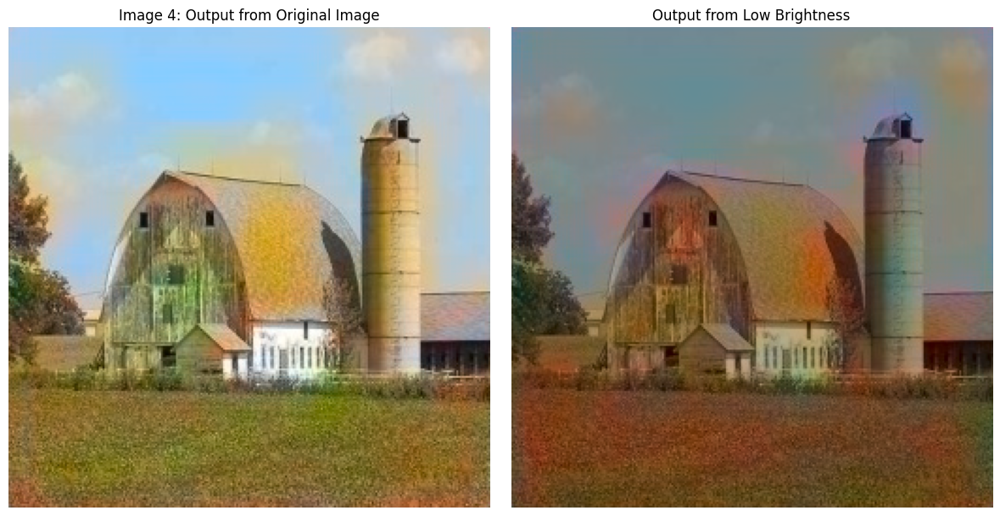

In [113]:
plot_colorized_modified(L_channels_raw_dark, ab_predicteds_dark, rgbs_first,"Low Brightness", False)

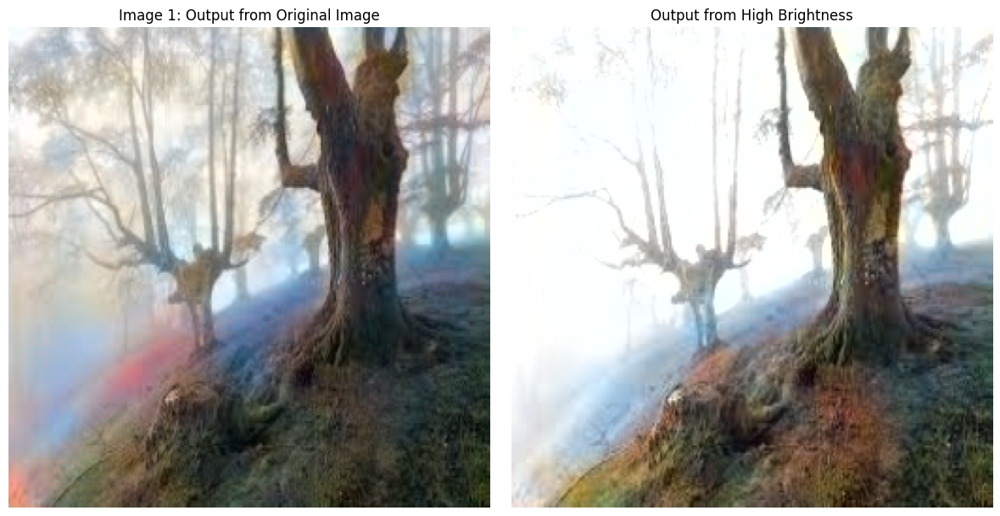

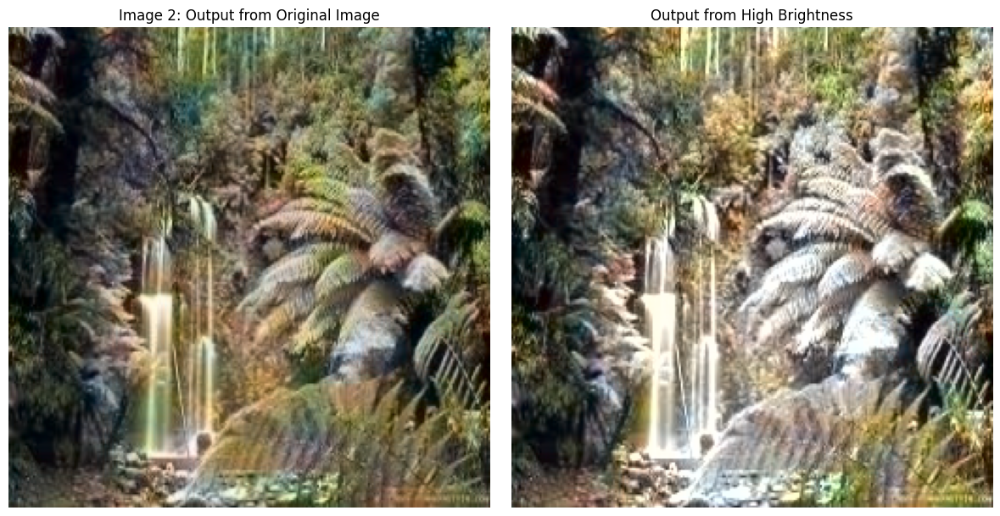

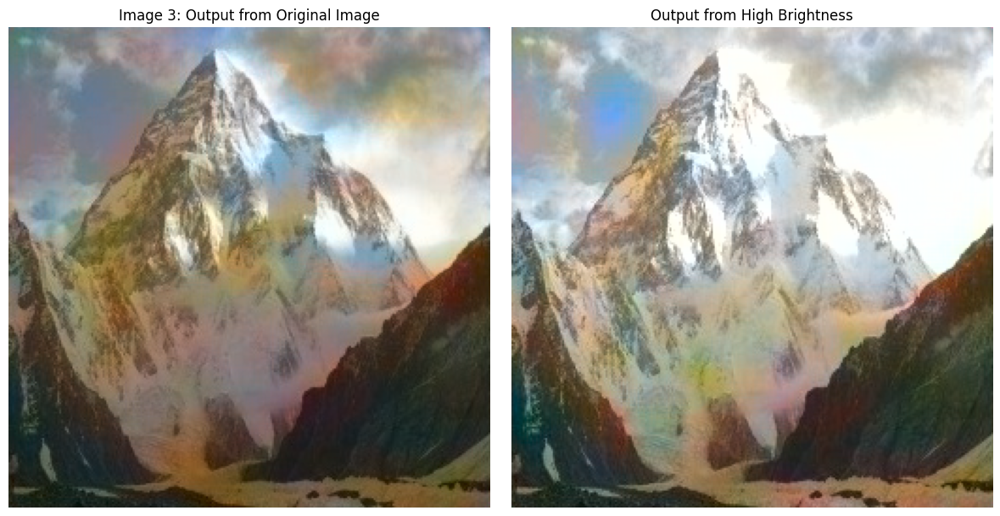

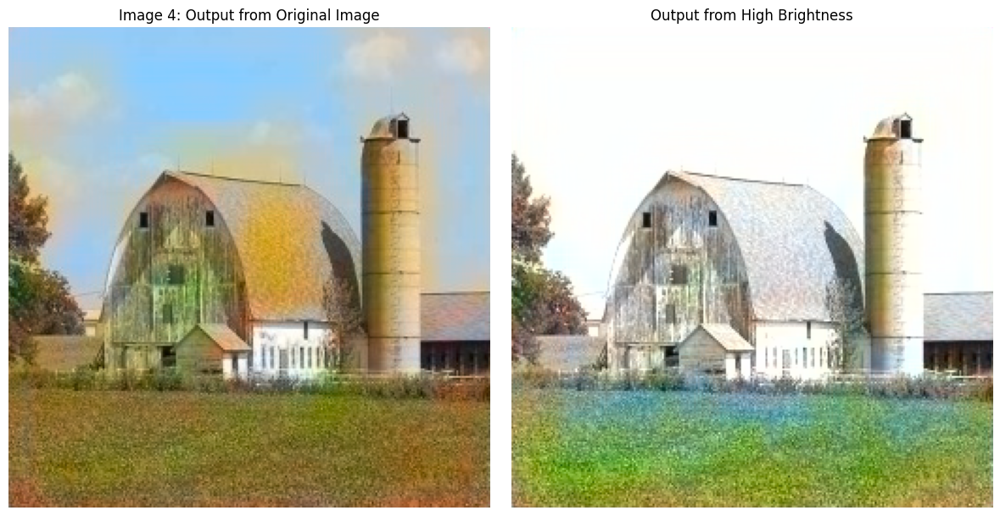

In [114]:
plot_colorized_modified(L_channels_raw_bright, ab_predicteds_bright, rgbs_first,"High Brightness", False)

## Answers to questions in the project documentation

**3.** The second method is generally expected to look more natural because it starts from the original RGB image and extracts the L channel in a standard Lab conversion, so the luminance information is more consistent with the image content. The first method uses a grayscale image repeated across three channels, which can reduce color realism.

**4(a) Rotation.** After rotating the input by 45 degrees and rotating the colorized result back by 45 degrees in the opposite direction, the output should remain broadly aligned with the original image, but some border areas and fine details may become less accurate because of interpolation and padding effects.

**4(b) Gaussian Noise.** Adding Gaussian noise to the L channel mainly affects regions with low contrast, smooth shading, and fine texture, because those regions depend heavily on luminance consistency. Stronger visual artifacts are usually seen where the image has weak edges or subtle tonal changes.

**4(c) Brightness.** Multiplying the L channel by 0.7 darkens the input, while multiplying by 1.3 brightens it. The output colors should change to some extent, but not perfectly proportionally, because the model predicts chroma from learned patterns rather than explicitly modeling illumination.

Overall, the second method usually produces the more natural-looking result, while the first method is better suited for the robustness experiments required in part 4.